# Determination of the e/m Ratio of the Electron
## Atomic and Molecular Physics Laboratory - Experiment 04
**Author**: IBRAHIM H.I. ABUSHAWISH  
**Department**: Department of Physics, Istanbul University  

This notebook performs the rigorous numerical evaluation, statistical analysis, linear regression, and artifact generation for the determination of the electron specific charge ($e/m_e$) using a cathode ray deflection tube and Helmholtz coils.

### Critical Note on Helmholtz Formula and Vacuum Permeability $\mu_0$:
In the laboratory manual, Equation~(7) states:
$$B = \mu_0 \frac{N R^2}{(R^2 + a^2/4)^{3/2}} I \quad \text{with } \mu_0 = 1$$
and gives the relation as $B = 4.25 \times 10^{-3}\text{ m}^{-1} I$.

This formulation contains two explicit errors:
1. **Value and Dimensions of $\mu_0$**: In SI units, the permeability of free space is $\mu_0 = 4\pi \times 10^{-7}\text{ T}\cdot\text{m/A} \approx 1.256637 \times 10^{-6}\text{ H/m}$. Setting $\mu_0 = 1$ is physically and dimensionally invalid in the SI system; the author intended relative permeability $\mu_r \approx 1$ for air.
2. **Coil Constant and Units**: The geometric factor is:
   $$\left(\frac{4}{5}\right)^{3/2} \frac{N}{R} = (0.715542) \times \frac{320}{0.068} = 3367.255\text{ m}^{-1}$$
   Multiplying by the physical constant $\mu_0 = 4\pi \times 10^{-7}\text{ T}\cdot\text{m/A}$ yields the exact calibration factor:
   $$k_{B,\text{exact}} = \left(\frac{4}{5}\right)^{3/2} \frac{\mu_0 N}{R} = 4.23142 \times 10^{-3}\text{ T/A} \quad (\text{Tesla per Ampere})$$
   The manual approximated this as $4.25 \times 10^{-3}$, erroneously appending $\text{m}^{-1}$.

Below, we compute both $B_{\text{exact}}$ and $B_{\text{manual}}$, evaluating the precise impact on the resulting specific charge $e/m_e$.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Ensure output directories exist
os.makedirs('../plots', exist_ok=True)
os.makedirs('../report/tables', exist_ok=True)

# Plot styling configuration
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.dpi': 300,
    'font.family': 'serif'
})

### 1. Fundamental Constants and Coil Geometry
Defining the exact physical constants in SI units:
- Vacuum permeability: $\mu_0 = 4\pi \times 10^{-7}\text{ T}\cdot\text{m/A}$
- Coil turns: $N = 320$
- Coil radius: $R = 0.068\text{ m}$
- Elementary charge: $e = 1.602176634 \times 10^{-19}\text{ C}$
- Electron rest mass: $m_e = 9.1093837015 \times 10^{-31}\text{ kg}$
- Accepted specific charge: $e/m_e = 1.758820 \times 10^{11}\text{ C/kg}$

In [2]:
# Fundamental SI Constants
mu_0 = 4.0 * np.pi * 1e-7      # T * m / A (H/m)
e_lit = 1.602176634e-19       # C
m_e_lit = 9.1093837015e-31    # kg
em_lit = e_lit / m_e_lit      # C/kg (1.758820e11 C/kg)

# Helmholtz Coil Geometry
N_turns = 320                 # turns per coil
R_coil = 0.068                # m (6.8 cm)

# Exact Helmholtz coil calibration factor:
k_B_exact = ((4.0 / 5.0)**1.5) * (mu_0 * N_turns / R_coil)
k_B_manual = 4.25e-3          # Nominal value from manual

print(f"Exact Helmholtz factor:  k_B_exact  = {k_B_exact:.6e} T/A ({k_B_exact*1e3:.4f} mT/A)")
print(f"Manual nominal factor:   k_B_manual = {k_B_manual:.6e} T/A ({k_B_manual*1e3:.4f} mT/A)")
print(f"Relative difference:     {abs(k_B_exact - k_B_manual)/k_B_exact * 100:.3f}%")

# Load raw experimental dataset
data_path = '../DATA/data.csv'
df = pd.read_csv(data_path)
print("\nRaw Experimental Data:")
display(df)

Exact Helmholtz factor:  k_B_exact  = 4.231418e-03 T/A (4.2314 mT/A)
Manual nominal factor:   k_B_manual = 4.250000e-03 T/A (4.2500 mT/A)
Relative difference:     0.439%

Raw Experimental Data:


,Trial,V_kV,I_A,r_cm,B_Tesla,em_recorded_C_per_kg,Setup
0,1,2.0,0.29,21.25,0.001232,5.840000e+10,Setup 1
1,2,3.0,0.29,25.50,0.001232,6.080000e+10,Setup 1
2,3,3.6,0.42,18.50,0.001785,6.630000e+10,Setup 1
3,4,4.5,0.36,25.00,0.001530,6.310000e+10,Setup 1
4,5,4.0,0.25,32.50,0.001063,6.700000e+10,Setup 1
5,6,3.0,0.40,16.25,0.001700,2.358000e+11,Setup 2


### 2. Unit Conversions and Calculation of $B$ and $e/m_e$
Units are converted to SI:
$$V\ [\text{V}] = V\ [\text{kV}] \times 1000, \quad r\ [\text{m}] = r\ [\text{cm}] / 100$$
The magnetic field is calculated using the exact calibration factor:
$$B_{\text{exact}} = k_{B,\text{exact}} \cdot I$$
and the resulting specific charge is calculated via:
$$\frac{e}{m_e} = \frac{2V}{B^2 r^2}$$

In [3]:
# Unit conversions
df['V_V'] = df['V_kV'] * 1000.0
df['r_m'] = df['r_cm'] / 100.0

# Magnetic field calculations
df['B_exact_T'] = k_B_exact * df['I_A']
df['B_manual_T'] = k_B_manual * df['I_A']

# e/m calculations
df['em_exact_C_per_kg'] = 2.0 * df['V_V'] / ((df['B_exact_T']**2) * (df['r_m']**2))
df['em_manual_C_per_kg'] = 2.0 * df['V_V'] / ((df['B_manual_T']**2) * (df['r_m']**2))

# Error calculations against literature
df['error_abs_exact'] = np.abs(df['em_exact_C_per_kg'] - em_lit)
df['percent_error_exact'] = (df['error_abs_exact'] / em_lit) * 100.0

print("Processed Experimental Results with Exact B:")
for idx, row in df.iterrows():
    print(f"Trial {int(row['Trial'])} ({row['Setup']}): V = {row['V_V']:.0f} V, I = {row['I_A']:.2f} A, "
          f"r = {row['r_m']*100:.2f} cm, B_exact = {row['B_exact_T']*1e3:.4f} mT -> "
          f"e/m_exact = {row['em_exact_C_per_kg']:.4e} C/kg (Error: {row['percent_error_exact']:.2f}%)")

Processed Experimental Results with Exact B:
Trial 1 (Setup 1): V = 2000 V, I = 0.29 A, r = 21.25 cm, B_exact = 1.2271 mT -> e/m_exact = 5.8827e+10 C/kg (Error: 66.55%)
Trial 2 (Setup 1): V = 3000 V, I = 0.29 A, r = 25.50 cm, B_exact = 1.2271 mT -> e/m_exact = 6.1278e+10 C/kg (Error: 65.16%)
Trial 3 (Setup 1): V = 3600 V, I = 0.42 A, r = 18.50 cm, B_exact = 1.7772 mT -> e/m_exact = 6.6607e+10 C/kg (Error: 62.13%)
Trial 4 (Setup 1): V = 4500 V, I = 0.36 A, r = 25.00 cm, B_exact = 1.5233 mT -> e/m_exact = 6.2056e+10 C/kg (Error: 64.72%)
Trial 5 (Setup 1): V = 4000 V, I = 0.25 A, r = 32.50 cm, B_exact = 1.0579 mT -> e/m_exact = 6.7682e+10 C/kg (Error: 61.52%)
Trial 6 (Setup 2): V = 3000 V, I = 0.40 A, r = 16.25 cm, B_exact = 1.6926 mT -> e/m_exact = 7.9315e+10 C/kg (Error: 54.90%)


### 3. Statistical Analysis: Setup 1 vs Setup 2
Statistical analysis of Setup 1 (Trials 1-5) and comparison with Setup 2 (Trial 6).

In [4]:
# Split datasets
setup1_mask = df['Setup'] == 'Setup 1'
df_s1 = df[setup1_mask].copy()
row_s2 = df[~setup1_mask].iloc[0]

# Setup 1 statistical calculations (Exact B)
em_s1_exact = df_s1['em_exact_C_per_kg'].values
mean_em_s1 = np.mean(em_s1_exact)
std_em_s1 = np.std(em_s1_exact, ddof=1)
sem_em_s1 = std_em_s1 / np.sqrt(len(em_s1_exact))
rel_err_s1 = (np.abs(mean_em_s1 - em_lit) / em_lit) * 100.0

# Setup 2 values
em_s2_exact = row_s2['em_exact_C_per_kg']
em_s2_recorded = row_s2['em_recorded_C_per_kg']
rel_err_s2_rec = (np.abs(em_s2_recorded - em_lit) / em_lit) * 100.0

print(f"Setup 1 (Trials 1-5) Mean e/m: {mean_em_s1:.4e} +/- {sem_em_s1:.4e} C/kg")
print(f"Setup 1 Standard Deviation: {std_em_s1:.4e} C/kg")
print(f"Setup 1 Relative Error:     {rel_err_s1:.2f}%")
print(f"Setup 2 (Trial 6) Exact:    {em_s2_exact:.4e} C/kg")
print(f"Setup 2 Lab Sheet Recorded: {em_s2_recorded:.4e} C/kg (Error: {rel_err_s2_rec:.2f}%)")
print(f"Literature Standard:        {em_lit:.4e} C/kg")

Setup 1 (Trials 1-5) Mean e/m: 6.3290e+10 +/- 1.6700e+09 C/kg
Setup 1 Standard Deviation: 3.7343e+09 C/kg
Setup 1 Relative Error:     64.02%
Setup 2 (Trial 6) Exact:    7.9315e+10 C/kg
Setup 2 Lab Sheet Recorded: 2.3580e+11 C/kg (Error: 34.07%)
Literature Standard:        1.7588e+11 C/kg


### 4. Linear Regression Analysis
Fitting the relationship $2V = (e/m_e) \cdot (B_{\text{exact}} \cdot r)^2$ for Setup 1.

In [5]:
# Regression variables for Setup 1 using exact B
x_s1 = (df_s1['B_exact_T'].values * df_s1['r_m'].values)**2  # (B * r)^2 in T^2 * m^2
y_s1 = 2.0 * df_s1['V_V'].values                            # 2V in Volts

# Standard unconstrained linear regression: y = slope * x + intercept
reg = linregress(x_s1, y_s1)
slope_reg = reg.slope
intercept_reg = reg.intercept
r_squared = reg.rvalue**2
std_err_slope = reg.stderr

# Constrained fit through origin: y = slope * x
slope_origin = np.sum(x_s1 * y_s1) / np.sum(x_s1**2)
residuals_origin = y_s1 - slope_origin * x_s1
r_squared_origin = 1.0 - (np.sum(residuals_origin**2) / np.sum((y_s1 - np.mean(y_s1))**2))

print("Unconstrained Linear Fit (Exact B):")
print(f"  Slope (e/m) = {slope_reg:.4e} +/- {std_err_slope:.4e} C/kg")
print(f"  Intercept   = {intercept_reg:.2f} V")
print(f"  R^2         = {r_squared:.4f}")
print(f"  Error vs Lit= {abs(slope_reg - em_lit)/em_lit * 100:.2f}%")
print()

print("Constrained Fit (through origin):")
print(f"  Slope (e/m) = {slope_origin:.4e} C/kg")
print(f"  R^2         = {r_squared_origin:.4f}")
print(f"  Error vs Lit= {abs(slope_origin - em_lit)/em_lit * 100:.2f}%")

Unconstrained Linear Fit (Exact B):
  Slope (e/m) = 6.7365e+10 +/- 7.2470e+09 C/kg
  Intercept   = -398.22 V
  R^2         = 0.9664
  Error vs Lit= 61.70%

Constrained Fit (through origin):
  Slope (e/m) = 6.3852e+10 C/kg
  R^2         = 0.9637
  Error vs Lit= 63.70%


### 5. Figure Generation and Artifact Exports
Generating high-resolution publication figures saved directly to `../plots/`.

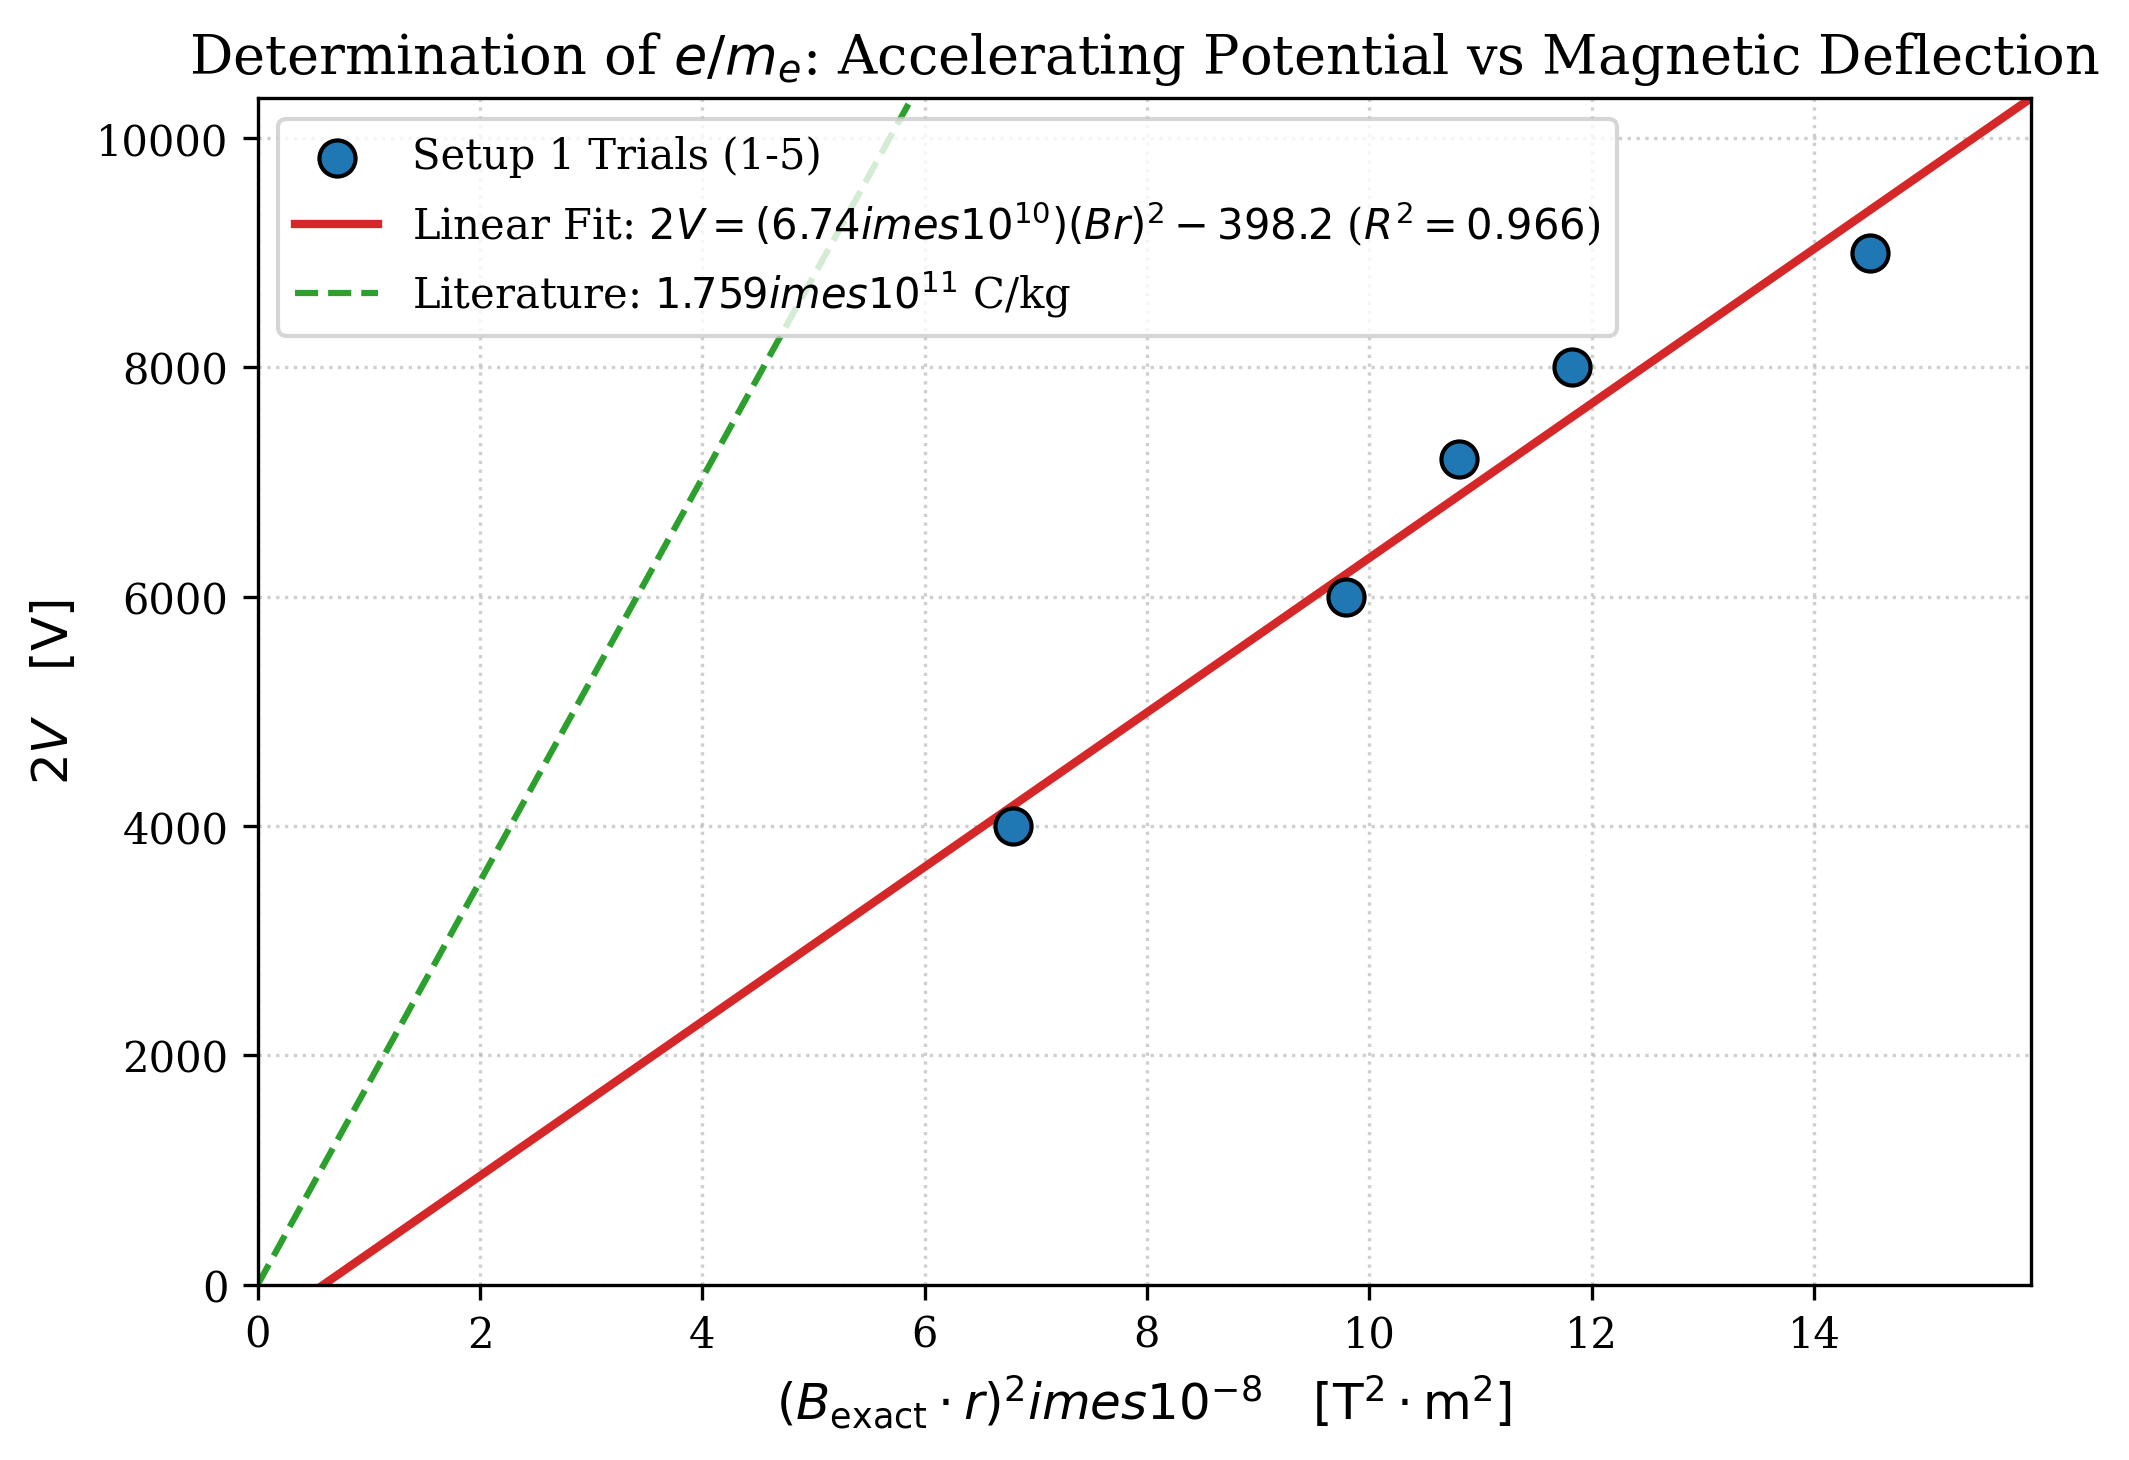

Saved Figure 1 to ../plots/linear_regression_2V_vs_B2r2.png


In [6]:
# Figure 1: Linear Regression Plot 2V vs (B_exact * r)^2
plt.figure(figsize=(7, 5))

# Plot experimental data points
plt.scatter(x_s1 * 1e8, y_s1, color='#1f77b4', s=75, edgecolors='k', zorder=5, label='Setup 1 Trials (1-5)')

# Fit line
x_fit = np.linspace(0, np.max(x_s1)*1.1, 100)
y_fit = slope_reg * x_fit + intercept_reg
plt.plot(x_fit * 1e8, y_fit, color='#d62728', lw=2, linestyle='-', 
         label=f'Linear Fit: $2V = ({slope_reg/1e10:.2f}\times 10^{{10}})(Br)^2 - {abs(intercept_reg):.1f}$ ($R^2={r_squared:.3f}$)')

# Literature comparison line (through origin)
y_lit = em_lit * x_fit
plt.plot(x_fit * 1e8, y_lit, color='#2ca02c', lw=1.5, linestyle='--', 
         label=f'Literature: $1.759\times 10^{{11}}$ C/kg')

plt.xlabel(r'$(B_{\mathrm{exact}} \cdot r)^2 	imes 10^{-8}\quad [\mathrm{T^2 \cdot m^2}]$')
plt.ylabel(r'$2V\quad [\mathrm{V}]$')
plt.title(r'Determination of $e/m_e$: Accelerating Potential vs Magnetic Deflection')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.xlim(0, np.max(x_s1 * 1e8) * 1.1)
plt.ylim(0, np.max(y_s1) * 1.15)
plt.tight_layout()

fig1_path = '../plots/linear_regression_2V_vs_B2r2.png'
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved Figure 1 to {fig1_path}")

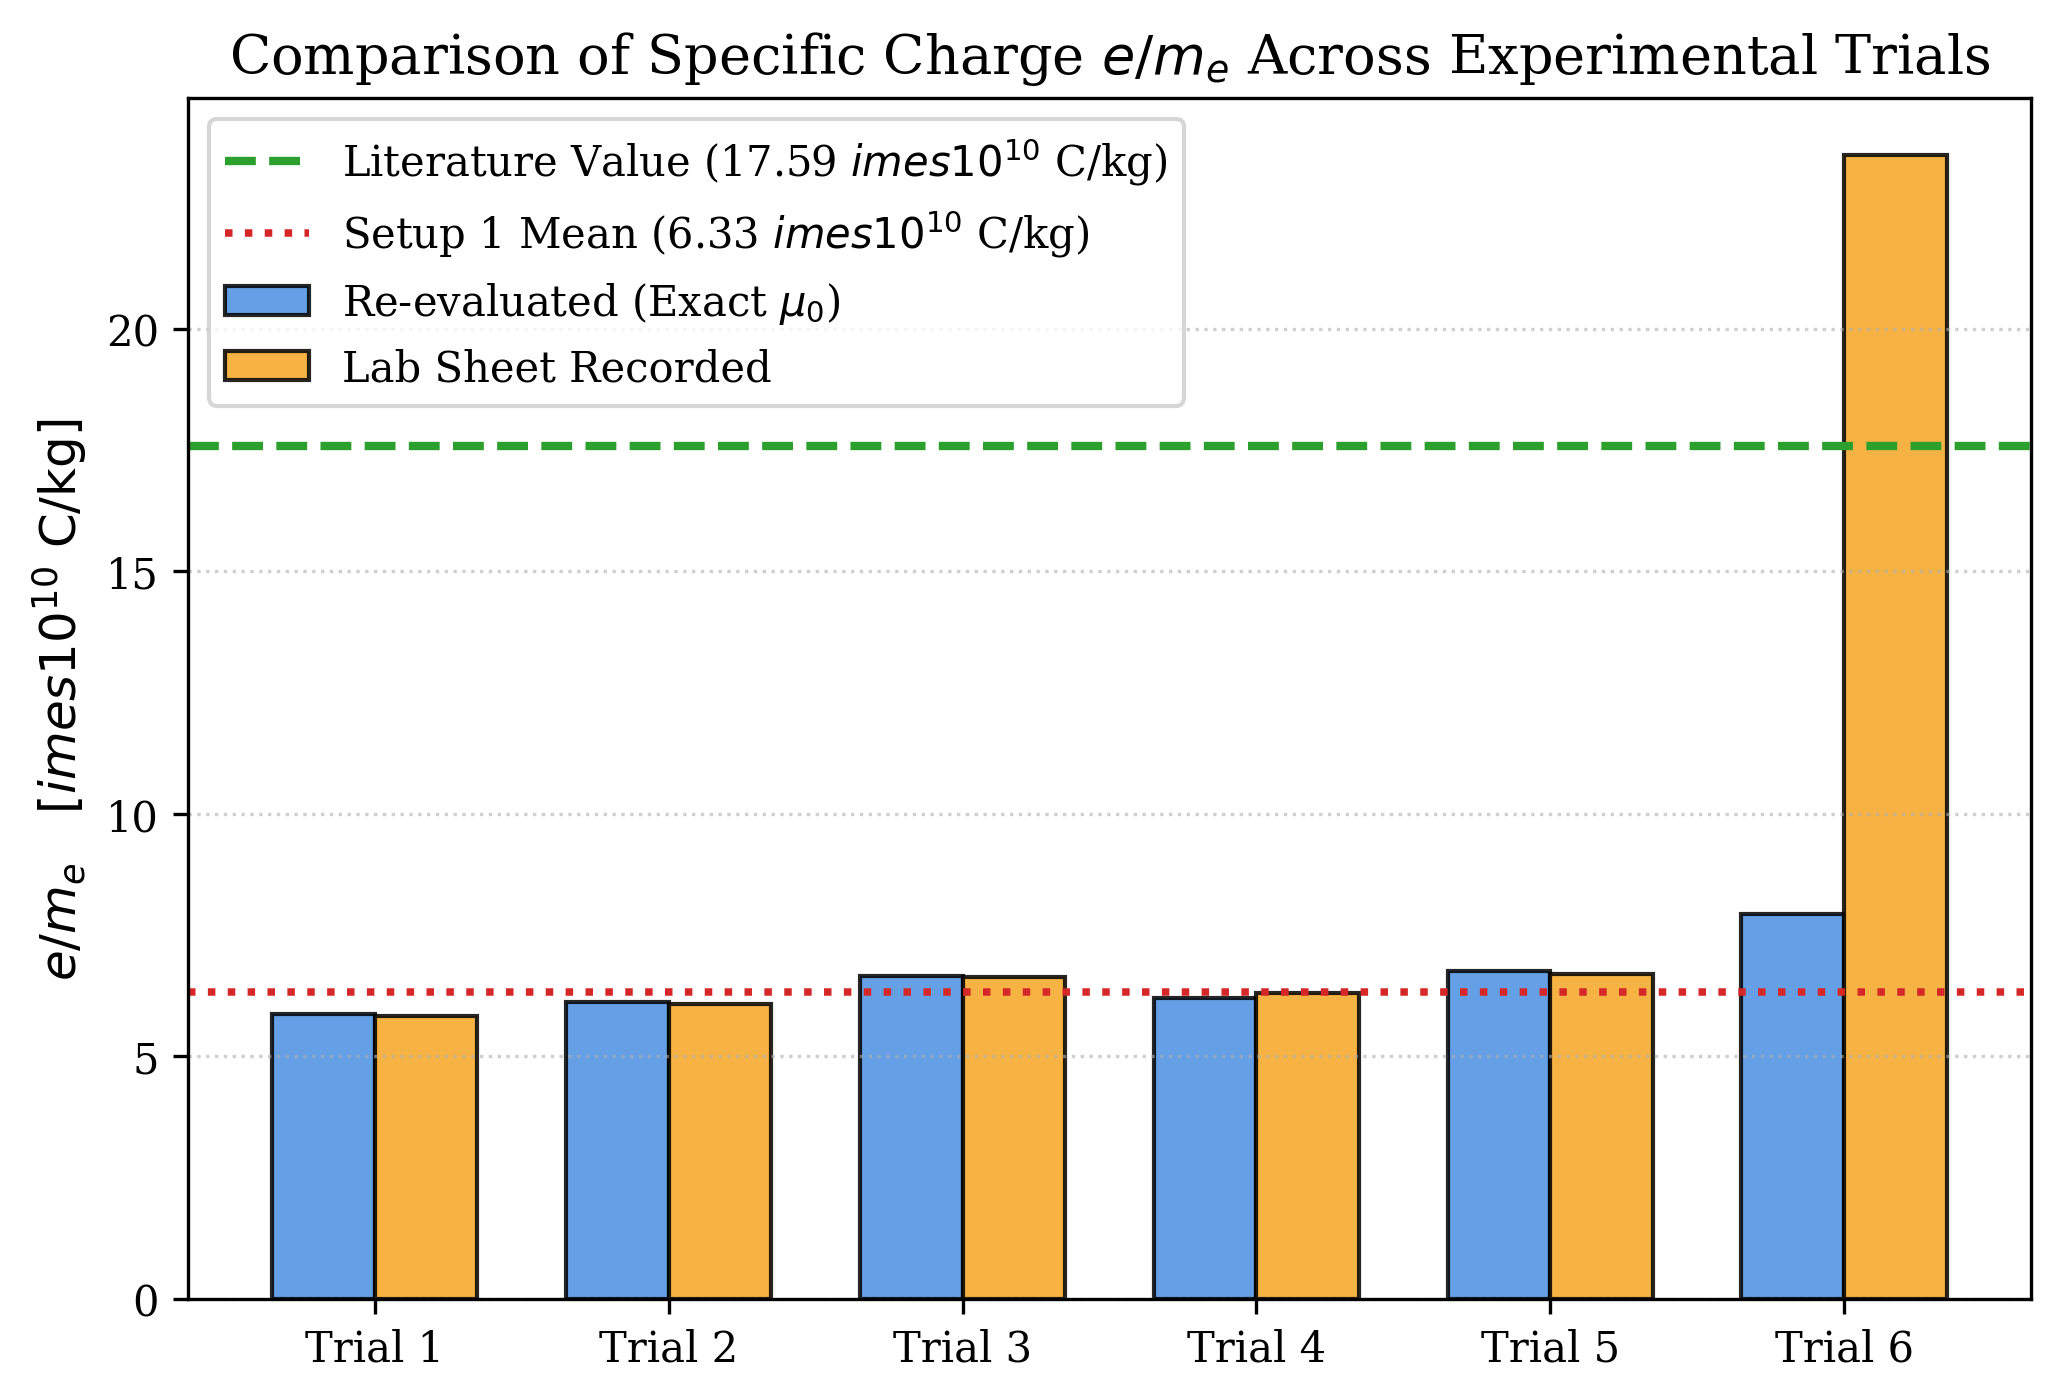

Saved Figure 2 to ../plots/em_ratio_trials.png


In [7]:
# Figure 2: Comparison of Experimental e/m across Trials
plt.figure(figsize=(7, 4.8))

trials = df['Trial'].values
em_exact_scaled = df['em_exact_C_per_kg'].values / 1e10
em_rec_scaled = df['em_recorded_C_per_kg'].values / 1e10

x_idx = np.arange(len(trials))
width = 0.35

plt.bar(x_idx - width/2, em_exact_scaled, width, label='Re-evaluated (Exact $\mu_0$)', color='#4a90e2', edgecolor='black', alpha=0.85)
plt.bar(x_idx + width/2, em_rec_scaled, width, label='Lab Sheet Recorded', color='#f5a623', edgecolor='black', alpha=0.85)

# Literature reference line
plt.axhline(em_lit / 1e10, color='#2ca02c', linestyle='--', linewidth=2, label=f'Literature Value ({em_lit/1e10:.2f} $\times 10^{{10}}$ C/kg)')

# Setup 1 mean line
plt.axhline(mean_em_s1 / 1e10, color='#d62728', linestyle=':', linewidth=1.8, label=f'Setup 1 Mean ({mean_em_s1/1e10:.2f} $\times 10^{{10}}$ C/kg)')

plt.xticks(x_idx, [f'Trial {int(t)}' for t in trials])
plt.ylabel(r'$e/m_e\quad [	imes 10^{10}\ \mathrm{C/kg}]$')
plt.title(r'Comparison of Specific Charge $e/m_e$ Across Experimental Trials')
plt.legend(loc='upper left', frameon=True)
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()

fig2_path = '../plots/em_ratio_trials.png'
plt.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved Figure 2 to {fig2_path}")

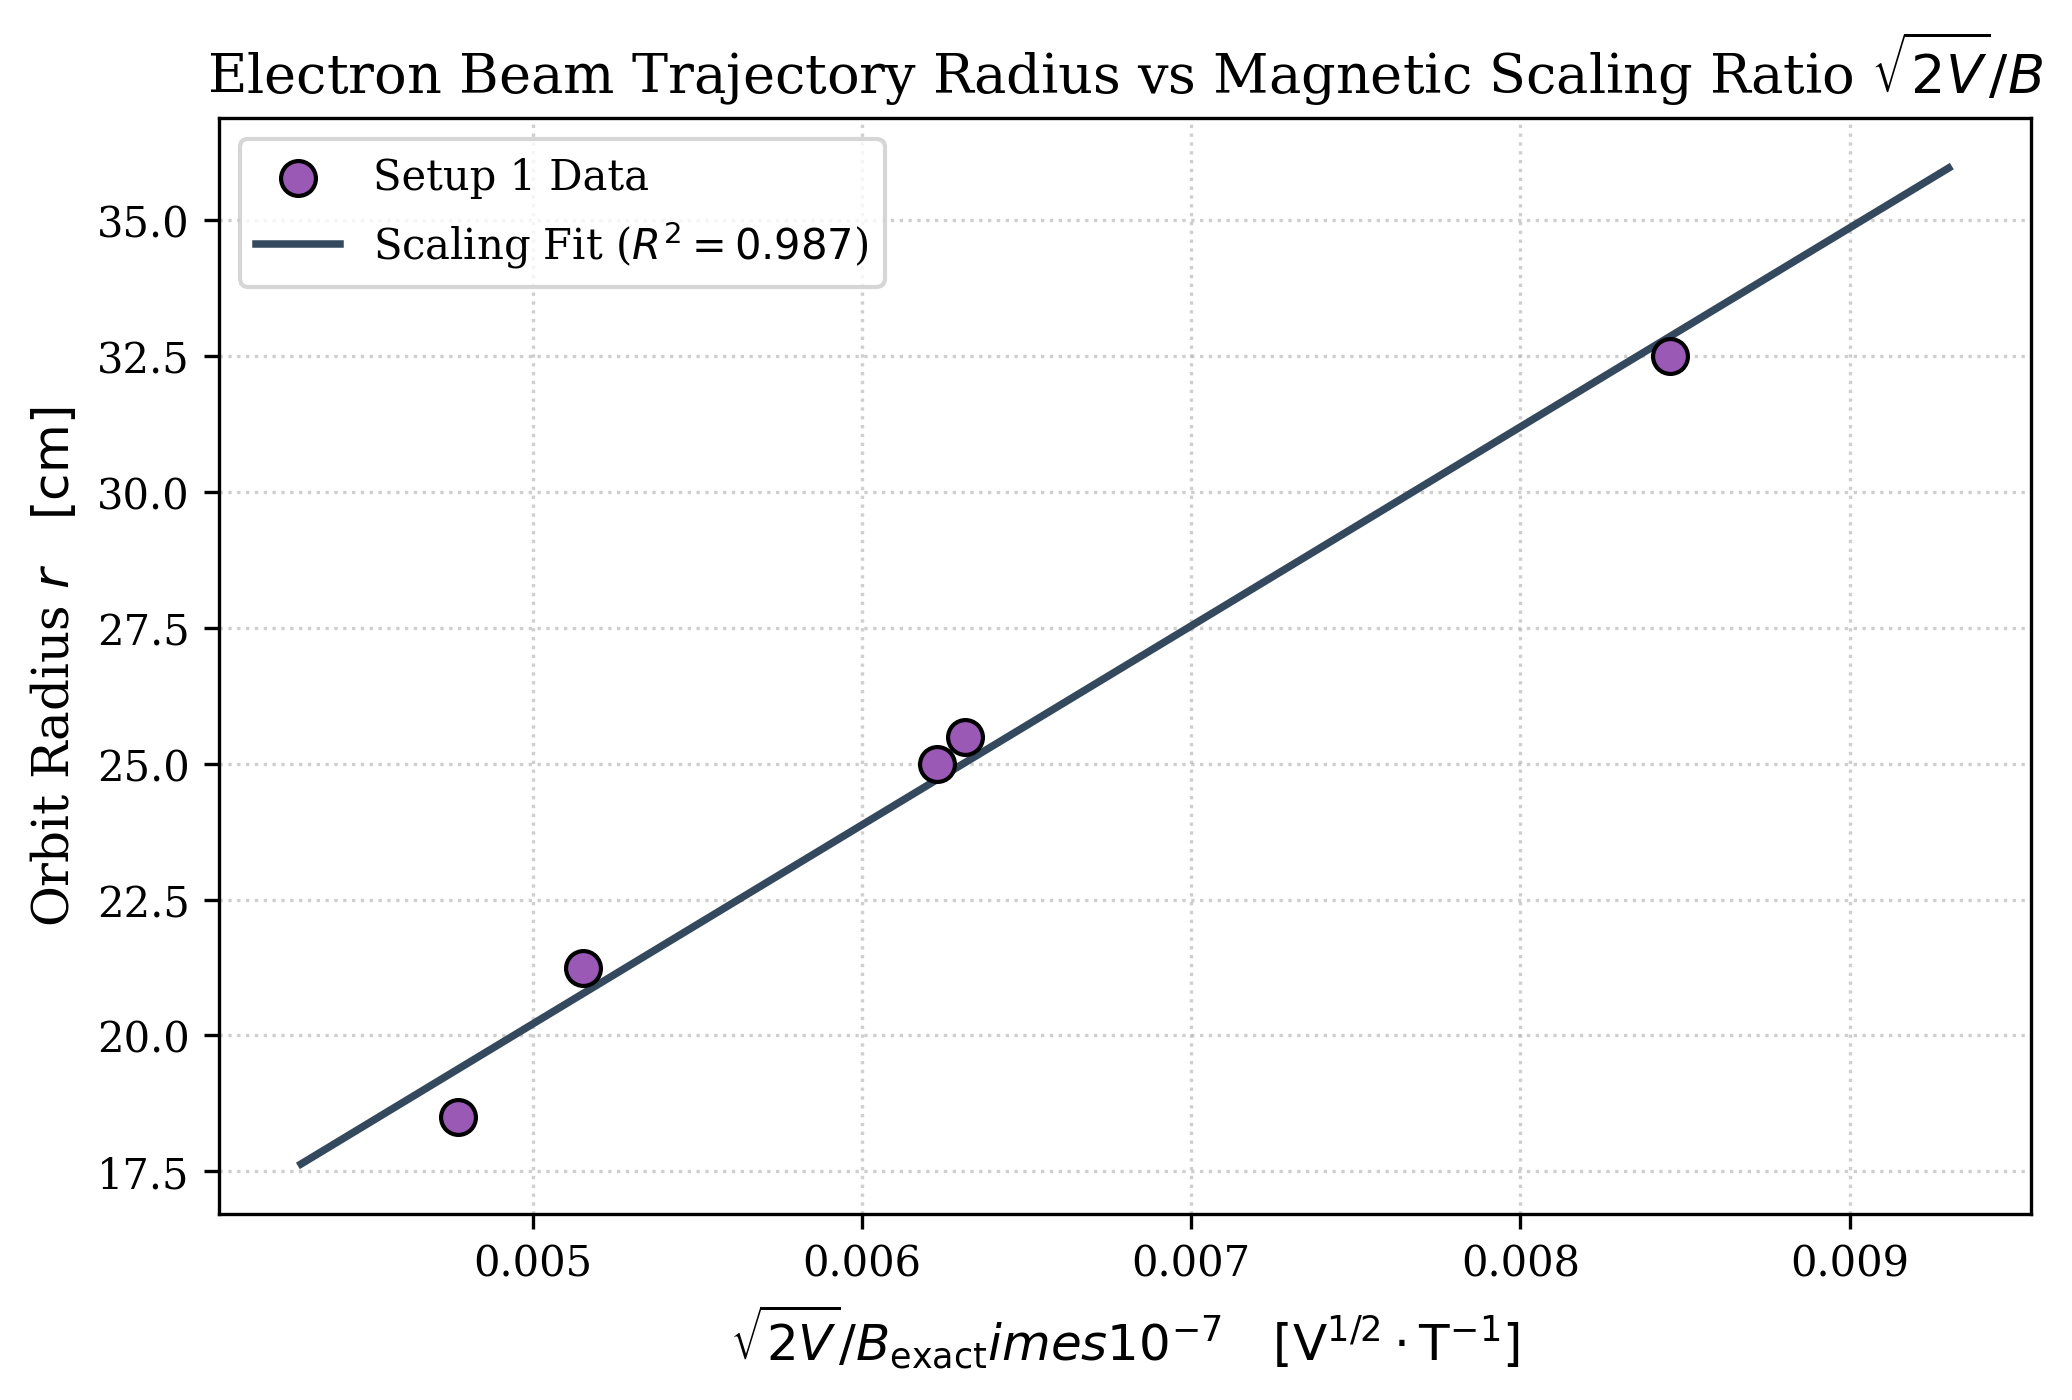

Saved Figure 3 to ../plots/orbit_radius_vs_scaling.png


In [8]:
# Figure 3: Orbital Radius vs Scaling Parameter sqrt(2V)/B_exact
plt.figure(figsize=(7, 4.8))

# Trajectory scaling: r = (1/sqrt(e/m)) * (sqrt(2V)/B)
scaling_param_s1 = np.sqrt(2.0 * df_s1['V_V'].values) / df_s1['B_exact_T'].values

plt.scatter(scaling_param_s1 / 1e7, df_s1['r_m'].values * 100, color='#9b59b6', s=70, edgecolors='k', zorder=5, label='Setup 1 Data')

# Linear fit for r vs sqrt(2V)/B
reg_scale = linregress(scaling_param_s1, df_s1['r_m'].values)
fit_x = np.linspace(np.min(scaling_param_s1)*0.9, np.max(scaling_param_s1)*1.1, 100)
fit_y = (reg_scale.slope * fit_x + reg_scale.intercept) * 100
plt.plot(fit_x / 1e7, fit_y, color='#34495e', lw=1.8, linestyle='-', 
         label=f'Scaling Fit ($R^2={reg_scale.rvalue**2:.3f}$)')

plt.xlabel(r'$\sqrt{2V}/B_{\mathrm{exact}} 	imes 10^{-7}\quad [\mathrm{V^{1/2} \cdot T^{-1}}]$')
plt.ylabel(r'Orbit Radius $r\quad [\mathrm{cm}]$')
plt.title(r'Electron Beam Trajectory Radius vs Magnetic Scaling Ratio $\sqrt{2V}/B$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

fig3_path = '../plots/orbit_radius_vs_scaling.png'
plt.savefig(fig3_path, dpi=300)
plt.show()
print(f"Saved Figure 3 to {fig3_path}")

### 6. Export Processed Data Tables
Exporting formatted tables to `../report/tables/` for LaTeX document integration.

In [9]:
# Table 1: Complete experimental measurements table
table1_export = pd.DataFrame({
    'Trial': df['Trial'].astype(int),
    'V_kV': df['V_kV'].map(lambda x: f"{x:.1f}"),
    'V_V': df['V_V'].map(lambda x: f"{x:.0f}"),
    'I_A': df['I_A'].map(lambda x: f"{x:.2f}"),
    'r_cm': df['r_cm'].map(lambda x: f"{x:.2f}"),
    'B_manual_mT': (df['B_manual_T'] * 1e3).map(lambda x: f"{x:.3f}"),
    'B_exact_mT': (df['B_exact_T'] * 1e3).map(lambda x: f"{x:.3f}"),
    'em_rec': (df['em_recorded_C_per_kg'] / 1e10).map(lambda x: f"{x:.2f}"),
    'em_calc': (df['em_exact_C_per_kg'] / 1e10).map(lambda x: f"{x:.2f}"),
    'Error_pct': df['percent_error_exact'].map(lambda x: f"{x:.1f}"),
    'Setup': df['Setup']
})

t1_path = '../report/tables/table1_measurements.csv'
table1_export.to_csv(t1_path, index=False)
print(f"Exported Table 1 to {t1_path}")
display(table1_export)

# Table 2: Statistical summary table
table2_export = pd.DataFrame([
    {
        'Method': 'Setup 1 Direct Mean (Exact B)',
        'em_val': f"{mean_em_s1/1e10:.2f} +/- {sem_em_s1/1e10:.2f}",
        'Abs_Error': f"{abs(mean_em_s1 - em_lit)/1e10:.2f}",
        'Rel_Error_pct': f"{rel_err_s1:.1f}",
        'R_squared': 'N/A'
    },
    {
        'Method': 'Setup 1 Linear Fit (Exact B)',
        'em_val': f"{slope_reg/1e10:.2f} +/- {std_err_slope/1e10:.2f}",
        'Abs_Error': f"{abs(slope_reg - em_lit)/1e10:.2f}",
        'Rel_Error_pct': f"{abs(slope_reg - em_lit)/em_lit * 100:.1f}",
        'R_squared': f"{r_squared:.4f}"
    },
    {
        'Method': 'Setup 2 (Trial 6, Lab Sheet)',
        'em_val': f"{em_s2_recorded/1e10:.2f}",
        'Abs_Error': f"{abs(em_s2_recorded - em_lit)/1e10:.2f}",
        'Rel_Error_pct': f"{rel_err_s2_rec:.1f}",
        'R_squared': 'N/A'
    },
    {
        'Method': 'Literature Accepted Value',
        'em_val': f"{em_lit/1e10:.2f}",
        'Abs_Error': '0.00',
        'Rel_Error_pct': '0.0',
        'R_squared': '1.0000'
    }
])

t2_path = '../report/tables/table2_summary.csv'
table2_export.to_csv(t2_path, index=False)
print(f"Exported Table 2 to {t2_path}")
display(table2_export)

Exported Table 1 to ../report/tables/table1_measurements.csv


,Trial,V_kV,V_V,I_A,r_cm,B_manual_mT,B_exact_mT,em_rec,em_calc,Error_pct,Setup
0,1,2.0,2000,0.29,21.25,1.233,1.227,5.84,5.88,66.6,Setup 1
1,2,3.0,3000,0.29,25.50,1.233,1.227,6.08,6.13,65.2,Setup 1
2,3,3.6,3600,0.42,18.50,1.785,1.777,6.63,6.66,62.1,Setup 1
3,4,4.5,4500,0.36,25.00,1.530,1.523,6.31,6.21,64.7,Setup 1
4,5,4.0,4000,0.25,32.50,1.062,1.058,6.70,6.77,61.5,Setup 1
5,6,3.0,3000,0.40,16.25,1.700,1.693,23.58,7.93,54.9,Setup 2


Exported Table 2 to ../report/tables/table2_summary.csv


,Method,em_val,Abs_Error,Rel_Error_pct,R_squared
0,Setup 1 Direct Mean (Exact B),6.33 +/- 0.17,11.26,64.0,N/A
1,Setup 1 Linear Fit (Exact B),6.74 +/- 0.72,10.85,61.7,0.9664
2,"Setup 2 (Trial 6, Lab Sheet)",23.58,5.99,34.1,N/A
3,Literature Accepted Value,17.59,0.00,0.0,1.0000
